# Modulo 1 - Fondamenti di Machine Learning


ITS Apulia Digital Academy - ML per il Mondo del Lavoro



---


In [3]:
# ----------------------------------------------------------------
# CELLA DI SETUP - eseguire questa cella prima di tutte le altre
# ----------------------------------------------------------------

import numpy as np          # calcolo numerico (array, operazioni matematiche)
import pandas as pd         # tabelle e dataframe
import matplotlib.pyplot as plt  # grafici

# Impostazioni globali dei grafici: dimensione, griglia leggera
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"]      = True
plt.rcParams["grid.alpha"]     = 0.3


---
## Sezione 0 - Statistica Essenziale per ML

La statistica e il linguaggio su cui si basa ogni algoritmo di ML.
Prima di costruire qualsiasi modello, i dati vanno capiti attraverso
le loro proprieta statistiche di base.


### Esercizio S0.1 - Media, Mediana e Varianza

---

**Dati:** stipendi annui (in euro) di 8 persone in una piccola azienda

```
stipendi = [28000, 32000, 34000, 35000, 36000, 38000, 42000, 350000]
```

**Formule da implementare:**

| Misura | Formula | Note |
|--------|---------|------|
| Media  | mu = (1/n) * somma(xi) | sensibile agli outlier |
| Mediana | valore centrale dopo ordinamento | robusta agli outlier |
| Varianza | sigma^2 = (1/n) * somma((xi - mu)^2) | dispersione attorno alla media |
| Deviazione std | sigma = radice(sigma^2) | stessa unita dei dati |

**Cosa fare:**
1. Calcola le quattro misure con NumPy (`np.mean`, `np.median`, `np.var`, `np.std`)
2. Stampa i valori
3. Aggiungi un commento che spiega quale misura e piu rappresentativa e perche

**Concetto chiave:** con un outlier molto grande (il CEO a 350.000 euro),
la media viene trascinata verso l'alto e non e piu rappresentativa.
In ML questo ha conseguenze concrete: se usiamo la media per imputare
i valori mancanti di uno stipendio, inseriamo un valore fuorviante per
la quasi totalita dei dipendenti.

```
         28k  32k  34k  35k  36k  38k  42k          350k
          |    |    |    |    |    |    |              |
-----+----+----+----+----+----+----+----+----...-------+----->
     0                              ^                       stipendio
                                 mediana
                                 35.500
                                                  ^
                                               media
                                              74.375
```


In [3]:
# ----------------------------------------------------------------
# Esercizio S0.1 - Media, Mediana e Varianza
#
# ----------------------------------------------------------------

# TODO 1: Calcola le quattro misure con NumPy (`np.mean`, `np.median`, `np.var`, `np.std`)
# TODO 2: Stampa i valori
# TODO 3: Aggiungi un commento che spiega quale misura e piu rappresentativa e perche

#1 
stipendi= np.array([28000, 32000, 34000, 35000, 36000, 38000, 42000, 350000])

# np.mean: somma tutti i valori e divide per n
# Problema: un solo valore molto alto (350.000) sposta la media verso di se
media = np.mean(stipendi)

# np.median: ordina l'array e prende il valore centrale
# Con 8 elementi (numero pari) fa la media dei due centrali: (35000+36000)/2
# Non risente dei valori estremi
mediana = np.median(stipendi)


# Misura quanto i valori si allontanano dalla media: valori lontani pesano di piu
# perche l'errore viene elevato al quadrato
varianza = np.var(stipendi)

# np.std: radice quadrata della varianza
# Torna nella stessa unita dei dati (euro, non euro al quadrato)
# Permette di dire: "i dati si discostano dalla media di circa X euro"
std = np.std(stipendi)

# Stampa compatta: una riga per misura
print("Media:          {:>10,.0f} euro  <- distorta dal CEO".format(media)) 
print("Mediana:        {:>10,.0f} euro  <- piu rappresentativa".format(mediana))
print("Varianza:       {:>10,.0f} euro^2".format(varianza))
print("Dev. Standard:  {:>10,.0f} euro".format(std))


Media:              74,375 euro  <- distorta dal CEO
Mediana:            35,500 euro  <- piu rappresentativa
Varianza:       10,867,484,375 euro^2
Dev. Standard:     104,247 euro


### Esercizio S0.2 - Correlazione tra Variabili

---

**Dati:** ore di studio e voti per 8 studenti

```
ore_studio = [1, 2, 3, 4, 5, 6, 7, 8]
voti       = [18, 20, 22, 24, 25, 27, 29, 30]
```

**Formula - Correlazione di Pearson:**

```
         somma( (xi - x_medio) * (yi - y_medio) )
r = -----------------------------------------------
     radice( somma((xi-x_medio)^2) ) * radice( somma((yi-y_medio)^2) )
```

Il risultato `r` e sempre compreso tra -1 e +1:

```
  r = -1          r = 0           r = +1
  (y)              (y)              (y)
   |  *             |  * *           |          *  *
   | *              | * *  *         |       *  *
   |*               |* * * *         |    *  *
   *                |  * * *         | *  *
  -+------>(x)     -+------>(x)     -+------>(x)
  relazione         nessuna          relazione
  inversa           relazione        diretta
```

**Attenzione:** correlazione non implica causalita.
Esempio classico: gelati venduti e annegamenti crescono insieme (r alto)
perche entrambi dipendono dalla temperatura esterna, non l'uno dall'altro.

**Cosa fare:**
1. Calcola `r` con `np.corrcoef` ed estrai il valore dalla matrice risultante
2. Aggiungi una retta di tendenza con `np.polyfit` (grado 1)
3. Traccia scatter plot con la retta di tendenza
4. Aggiungi un commento sull'interpretazione di `r`


[[1.         0.99711126]
 [0.99711126 1.        ]]
l indice di correlazione è 0.997
i coeff angolare e la costante sono:
1.7261904761904758 16.607142857142858


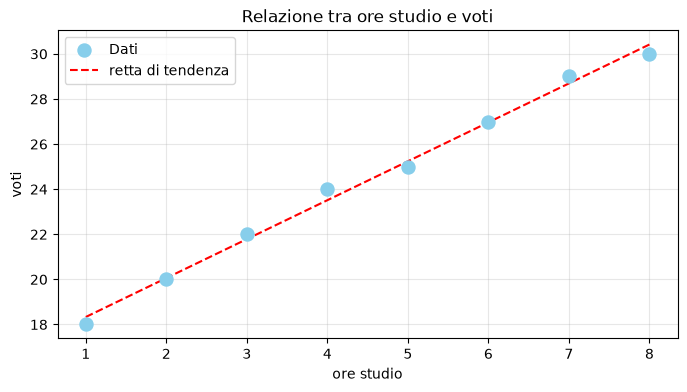

In [23]:
# ----------------------------------------------------------------
# Esercizio S0.3 - Correlazione tra Variabili
#
# ----------------------------------------------------------------

# TODO 1: Calcola `r` con `np.corrcoef` ed estrai il valore dalla matrice risultante
# TODO 2: Aggiungi una retta di tendenza con `np.polyfit` (grado 1)
# TODO 3: Traccia scatter plot con la retta di tendenza
# TODO 4: Aggiungi un commento sull'interpretazione di `r`

ore_studio = np.array([1, 2, 3, 4, 5, 6, 7, 8])
voti       = np.array([18, 20, 22, 24, 25, 27, 29, 30])

# TODO 1
matrice= np.corrcoef(ore_studio, voti)
print(matrice)
r = matrice[0, 1]
print(f"l indice di correlazione è {r:.3f}")

#TODO 2
m, q= np.polyfit(ore_studio, voti, deg=1) #m= coeff angolare retta, q= costante, deg= grado funzione che nella retta è 1
print("i coeff angolare e la costante sono:")
print(m, q)

#TODO 3

#lo scatterplot è un grafico che va a rappresentare i dati in punti, mentre la retta serve a misurare la tendenza dei dati 
plt.figure()   #creiamo l'istanza
plt.scatter(ore_studio, voti, s= 88, color= "skyblue",  zorder=5, label="Dati" ) #creiamo lo scatterplot
plt.plot(ore_studio, m*ore_studio+q, color="red", linestyle= "--", label="retta di tendenza") #impostiamo la retta di tendenza
plt.legend()
plt.title("Relazione tra ore studio e voti")
plt.xlabel("ore studio")
plt.ylabel("voti")
plt.show()









### Esercizio S0.3 - Probabilita Condizionata

**Riferimento: Sezione 0 - Probabilita condizionata**

---

**Definizione:**

```
    P(A | B) = P(A e B) / P(B)          con P(B) > 0

    Si legge: "probabilita di A dato B"
    Ci si restringe ai soli casi in cui B e vero,
    e si chiede in quanti di quei casi e vero anche A.
```

**Scenario:** test diagnostico su 100 persone per una malattia

**Tabella di contingenza (dati osservati):**

| | Test Positivo | Test Negativo | Totale |
|---|---|---|---|
| **Malato** | 9 | 1 | 10 |
| **Sano** | 9 | 81 | 90 |
| **Totale** | 18 | 82 | 100 |

**Cosa fare:**
1. Calcola `P(Malato)`: quota di persone malate sul totale
2. Calcola `P(Positivo | Malato)`: tra i malati, quanti risultano positivi al test
3. Calcola `P(Positivo | Sano)`: tra i sani, quanti risultano positivi al test
4. Verifica numericamente l'uguaglianza `P(A|B) * P(B) = P(A e B)`

**Concetto chiave:** qui calcoliamo la probabilita nella direzione "naturale"
(dato che una persona e malata, qual e la probabilita che il test sia positivo).
Il problema opposto - dato un test positivo, qual e la probabilita di essere
davvero malati - richiede uno strumento diverso (il Teorema di Bayes), che
vedremo formalizzato e applicato alla classificazione nell'Unita 3.4 del corso.


In [41]:
# ----------------------------------------------------------------
# Esercizio S0.4 - Probabilita Condizionata
# Riferimento: Sezione 0 - Probabilita condizionata
# ----------------------------------------------------------------

# TODO 1: Calcola `P(Malato)`: quota di persone malate sul totale
# TODO 2: Calcola `P(Positivo | Malato)`: tra i malati, quanti risultano positivi al test
# TODO 3: Calcola `P(Positivo | Sano)`: tra i sani, quanti risultano positivi al test
# TODO 4: Verifica numericamente l'uguaglianza `P(A|B) * P(B) = P(A e B)`
malati_positivi=9
malati_negativi=1
sani_positivi=9
sani_negativi=81
sani= sani_positivi+ sani_negativi
malati= malati_negativi + malati_positivi
soggetti= sani+malati
print(malati)
print(soggetti)
#TODO 1
#dobbiamo calcolare la probabilità che un soggetto sia malato
p_malato= malati/soggetti
print(p_malato)

# TODO 2
# Calcola `P(Positivo | Malato)`: tra i malati, quanti risultano positivi al test
p_malati_positivi= malati_positivi/malati
print(f"la prob che i malati siano risultati positivi al test è \n{p_malati_positivi}")

# TODO 3 
#Calcola `P(Positivo | Sano)`: tra i sani, quanti risultano positivi al test
p_sani_positivi= sani_positivi/sani
print(f"la prob che i sani siano risultati positivi al test è \n{p_sani_positivi:.2f}")

# TODO 4
# P(Malato e Positivo): quota di persone ENTRAMBE malate e positive
# sul totale generale (non solo sui malati)
p_malato_e_positivo = malati_positivi / soggetti
# Verifica numericamente l'uguaglianza `P(A|B) * P(B) = P(A e B)`
verifica= p_malati_positivi* p_malato 
print(f"\nConfrontiamo la percentuale dei malati positivi p(A e B): {p_malato_e_positivo:.2f}\ncon la probabilità condizionata P(A|B)* P(B):{verifica:.2f}\nIL CONFRONTO è {p_malato_e_positivo==verifica}")






10
100
0.1
la prob che i malati siano risultati positivi al test è 
0.9
la prob che i sani siano risultati positivi al test è 
0.10

Confrontiamo la percentuale dei malati positivi p(A e B): 0.09
con la probabilità condizionata P(A|B)* P(B):0.09
IL CONFRONTO è False


---
## Unita 1.1 - Cos'e il Machine Learning

In questa unita si capisce la differenza tra ML e programmazione tradizionale
e si esplora la struttura di un progetto ML dalla raccolta dati al deploy.


### Esercizio 1.1.1 - Simulare i Primi Step della Pipeline ML

---

**Schema della Pipeline ML:**

```
  [1. Raccolta]  -->  [2. EDA]  -->  [3. Preparazione]  -->  [4. Training]  -->  [5. Deploy]
     dati grezzi       analisi       normalizzazione          modello             produzione
```

**In questo esercizio simuliamo i primi 3 step su dati sintetici.**

**Step 1 - Raccolta dati (simulata)**

Genera 100 esempi con NumPy dove:
- `x` e la feature (valori uniformi tra 0 e 10)
- `y` e il target costruito con una relazione lineare piu rumore:

```
    y = 2 * x + epsilon       dove epsilon ~ N(0, 1.5)
    (la vera relazione)           (rumore realistico)
```

**Step 2 - EDA (Exploratory Data Analysis)**

Calcola e stampa: media, minimo e massimo di `x` e di `y`.

**Step 3 - Normalizzazione Min-Max**

Trasforma `x` nell'intervallo [0, 1] con la formula:

```
    x_norm = x / max(x)

    prima:  x in [0, 10]
    dopo:   x_norm in [0, 1]
```

La normalizzazione e importante perche algoritmi come SVM e reti neurali
sono sensibili alla scala delle feature: una feature in [0, 10.000] dominerebbe
una feature in [0, 1] anche se entrambe fossero ugualmente informative.

**Cosa fare:** implementa i tre step e traccia uno scatter plot di `x_norm` vs `y`.


EDA - feature x:   media= 4.70,  min= 0.06, max= 9.87 
EDA - target  y:   media= 9.40,  min= -0.47, max= 20.91 
Dopo normalizzazione: [0.01, 1.00]


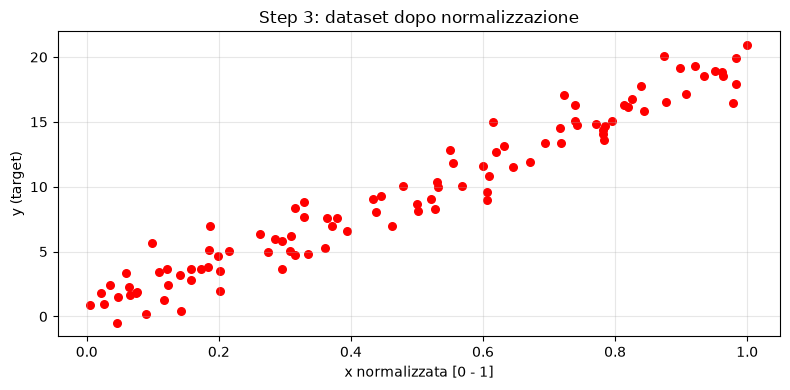

In [14]:
# ----------------------------------------------------------------
# Esercizio 1.1.1 - Simulare i Primi Step della Pipeline ML
#
# ----------------------------------------------------------------

# TODO: completa l'esercizio secondo la traccia sopra
#generiamo il seme di dati fissi
# STEP 1 - Raccolta dati (simulata)
np.random.seed(42)
n=100
x= np.random.uniform(0, 10, n)
rumore= np.random.normal(0, 1.5, n)
y= 2*x + rumore

# STEP 2 - EDA: statistiche descrittive di base
# Prima di modellare, capiamo i dati
print(f"EDA - feature x:   media= {x.mean():.2f},  min= {x.min():.2f}, max= {x.max():.2f} ")
print(f"EDA - target  y:   media= {y.mean():.2f},  min= {y.min():.2f}, max= {y.max():.2f} ")

#STEP 3 - NORMALIZZAZIONE min max
# Dividiamo per il massimo: il valore piu grande diventa 1, gli altri si scalano
# ATTENZIONE: il massimo si calcola SOLO sul training set (qui coincide con tutto)
x_norm = x / x.max()

print(f"Dopo normalizzazione: [{x_norm.min():.2f}, {x_norm.max():.2f}]")
# Grafico: scatter plot della feature normalizzata vs target
plt.figure()
plt.scatter(x_norm, y, alpha=1, color="red", s=30)
plt.xlabel("x normalizzata [0 - 1]")
plt.ylabel("y (target)")
plt.title("Step 3: dataset dopo normalizzazione")
plt.tight_layout()
plt.show()








### Esercizio 1.1.2 - ML vs Programmazione Tradizionale

---

**Il cambio di paradigma:**

```
  PROGRAMMAZIONE TRADIZIONALE          MACHINE LEARNING

  Dati  ---+                           Dati  ---+
            |---> [ REGOLE ]               |    |
  Regole ---+     manuali   ---> Output   |    +--> [ MODELLO ] ---> Output
  (scritte a                         Esempi---+    (apprende le
   mano)                             etichettati    regole dai dati)
```

**Scenario:** rilevatore di transazioni bancarie sospette

**Dati a disposizione:**

| id | importo (euro) | nazione |
|----|----------------|---------|
| 1  | 200            | IT      |
| 2  | 6000           | DE      |
| 3  | 4500           | IT      |
| 4  | 8000           | FR      |
| 5  | 100            | US      |

**Versione A - Rule-based (programmazione tradizionale):**
```
    se importo > 5000 E nazione != "IT"  -->  sospetta
```

**Versione B - Score-based (approccio ML-like):**
```
    score = 0.6 * (importo / 10000) + 0.4 * (nazione != "IT")
    se score > 0.5                       -->  sospetta
```

I pesi 0.6 e 0.4 simulano cio che un modello ML avrebbe APPRESO dai dati
storici etichettati. In un modello reale non li scriveresti a mano.

**Cosa fare:**
1. Crea il DataFrame con i dati della tabella
2. Implementa le due funzioni `rule_based` e `score_based`
3. Applica entrambe a ogni riga e aggiungi le colonne al DataFrame
4. Stampa il risultato e individua le differenze tra i due approcci


In [40]:
# ----------------------------------------------------------------
# Esercizio 1.1.2 - ML vs Programmazione Tradizionale
#
# ----------------------------------------------------------------

# TODO 1: Crea il DataFrame con i dati della tabella

transazioni= pd.DataFrame({
    "id" : [1, 2, 3, 4, 5],
    "importo(euro)" : [200, 6000, 4500, 8000, 100],
    "nazione": ["IT", "DE", "IT", "FR", "US"]
})
print(transazioni)

# TODO 2: Implementa le due funzioni `rule_based` e `score_based`

#METODO RULE BASED(programmazione tradizioinale)

def rule_based(importo, nazione):
    #se entrambe sono vere allore la trans è sospetta
    return importo > 5000 and nazione != "IT"

#METODO SCORE_BASED (ML)

def score_based(importo, nazione):
    score = 0.6 * (importo / 1000) + 0.4 * (nazione != "IT")
    sospetto = score > 0.5
    return round(score, 2), sospetto

# TODO 3: APPLICA LE FUNZIONI  e aggiungi colonne
#applichiamo riga per riga la funzione rule based
transazioni["rule"]= transazioni.apply(
    lambda r: rule_based(r["importo(euro)"], r["nazione"]) , axis= 1
) 
#applichiamo riga la funzione score based
transazioni[["score", "sospetto"]]= transazioni.apply(
    lambda r: pd.Series(score_based(r["importo(euro)"], r["nazione"])), axis= 1
)

print(transazioni.to_string(index=False))
print()
print("Differenza chiave: transazione 5 (100 euro, USA)")
print("  rule_based   -> non sospetta (importo troppo basso)")
print("  score_based  -> sospetta (nazione estera pesa 0.4, basta a superare 0.5)")


                                    
        





# TODO 3: Applica entrambe a ogni riga e aggiungi le colonne al DataFrame
# TODO 4: Stampa il risultato e individua le differenze tra i due approcci




   id  importo(euro) nazione
0   1            200      IT
1   2           6000      DE
2   3           4500      IT
3   4           8000      FR
4   5            100      US
 id  importo(euro) nazione  rule  score  sospetto
  1            200      IT False   0.12     False
  2           6000      DE  True   4.00      True
  3           4500      IT False   2.70      True
  4           8000      FR  True   5.20      True
  5            100      US False   0.46     False

Differenza chiave: transazione 5 (100 euro, USA)
  rule_based   -> non sospetta (importo troppo basso)
  score_based  -> sospetta (nazione estera pesa 0.4, basta a superare 0.5)


---
## Unita 1.2 - Dati, Modelli e Apprendimento

Un modello ML e una funzione parametrica f(x; theta) che trasforma
le feature in una predizione. Addestrarlo significa trovare i parametri
theta ottimali minimizzando l'errore sulle osservazioni disponibili.


### Esercizio 1.2.1 - Costruire e Esplorare un Dataset

---

**Notazione formale:**

```
  Dataset: D = { (x_i, y_i) }  per i = 1, ..., n

  x_i in R^d  = vettore delle feature dell'i-esima osservazione
  y_i         = target dell'i-esima osservazione
  n           = numero di osservazioni (righe)
  d           = numero di feature (colonne)
```

**Dati da generare:** dataset di 50 appartamenti

```
  Colonna     Tipo              Range
  --------    --------          --------
  mq          feature intera    [30, 150]
  piano       feature intera    [0, 10]
  zona        feature categ.    {A, B, C}
  prezzo      TARGET            calcolato
```

**Formula del target:**

```
    prezzo_i = 2000 * mq_i + 500 * piano_i + bonus_zona_i + epsilon_i

    dove  bonus_zona = 20000 se zona=A
                     = 10000 se zona=B
                     = 0     se zona=C
    e     epsilon ~ N(0, 5000)   (variabilita di mercato)
```

**Cosa fare:**
1. Genera le tre feature con `np.random.randint` e `np.random.choice`
2. Applica la formula del prezzo usando un dizionario per il bonus di zona
3. Crea il DataFrame pandas e mostra: `.head()`, `.describe()`, `.value_counts()` per zona


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.2.1 - Costruire e Esplorare un Dataset
#
# ----------------------------------------------------------------

# TODO 1: Genera le tre feature con `np.random.randint` e `np.random.choice`
# TODO 2: Applica la formula del prezzo usando un dizionario per il bonus di zona
# TODO 3: Crea il DataFrame pandas e mostra: `.head()`, `.describe()`, `.value_counts()` per zona




### Esercizio 1.2.2 - Spazio delle Ipotesi: Lineare vs Quadratico

---

**Definizione:**

Lo spazio delle ipotesi H e l'insieme di tutte le funzioni che un algoritmo
puo imparare. La scelta dell'algoritmo (o del grado del polinomio) stabilisce
quali relazioni il modello e CAPACE di rappresentare.

```
  Grado 1  ->  H = { f(x) = a*x + b }          solo rette
  Grado 2  ->  H = { f(x) = a*x^2 + b*x + c }  parabole e rette
  Grado k  ->  polinomi fino al grado k          sempre piu flessibili
```

**Dati sintetici** generati da una parabola con rumore:

```
    y = 0.5 * x^2 - x + 2 + epsilon       epsilon ~ N(0, 0.5)
    (relazione vera: parabola)             (rumore)
```

**Cosa succede con modelli di grado diverso:**

```
  y
  |      * *                   GRADO 1 (lineare):
  |    *     *    <- dati      non riesce a seguire la curvatura
  |   *         *              -> UNDERFITTING (bias elevato)
  |  *            *
  |  *                         GRADO 2 (quadratico):
  +--+---------+----> x        cattura la vera relazione
                               -> FITTING CORRETTO
```

**Formula del training MSE** (errore sui dati usati per il fit):

```
    MSE_train = (1/n) * somma( (y_pred_i - y_i)^2 )
```

**Cosa fare:**
1. Genera i dati con `np.random.seed(7)` e la formula sopra
2. Fitta grado 1 e grado 2 con `np.polyfit(x, y, deg=...)`
3. Calcola il training MSE per entrambi con `np.polyval`
4. Traccia entrambe le curve sullo stesso grafico e confronta


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.2.3 - Spazio delle Ipotesi: Lineare vs Quadratico
#
# ----------------------------------------------------------------

# TODO 1: Genera i dati con `np.random.seed(7)` e la formula sopra
# TODO 2: Fitta grado 1 e grado 2 con `np.polyfit(x, y, deg=...)`
# TODO 3: Calcola il training MSE per entrambi con `np.polyval`
# TODO 4: Traccia entrambe le curve sullo stesso grafico e confronta




---
## Unita 1.3 - Errore, Loss Function e Rischio Empirico

La loss function quantifica quanto e sbagliata una predizione.
Il training minimizza la media delle loss su tutti gli esempi
(Empirical Risk Minimization, ERM).


### Esercizio 1.3.1 - Confronto tra Loss Functions: MSE vs MAE

---

**Formule:**

```
  MSE (L2):  (1/n) * somma( (y_pred_i - y_real_i)^2 )   <- eleva al quadrato
  MAE (L1):  (1/n) * somma( |y_pred_i - y_real_i| )     <- valore assoluto
```

**Differenza chiave - comportamento con gli errori:**

```
  errore = 1  ->  MSE aggiunge  1,  MAE aggiunge  1
  errore = 2  ->  MSE aggiunge  4,  MAE aggiunge  2
  errore = 5  ->  MSE aggiunge 25,  MAE aggiunge  5
  errore = 10 ->  MSE aggiunge 100, MAE aggiunge 10
```

MSE penalizza esponenzialmente gli errori grandi: un singolo outlier
puo dominare il valore totale della loss e distorcere il training.

**Visualizzazione:**

```
  Loss
   |       /  <- MSE (parabola)
   |      /
   |    /
   |   / -- <- MAE (rette)
   |  /
   | /
   |/
   +--------> errore
   0
```

**Dati per questo esercizio:**

```
  y_real = [10, 20, 30, 40,  50]
  y_pred = [12, 18, 35, 38,  55]
```

**Cosa fare:**
1. Calcola MSE e MAE sul dataset originale
2. Sostituisci `y_real[4] = 200` (outlier) e ricalcola entrambe le metriche
3. Calcola di quante volte e aumentato ciascuna metrica
4. Conclude: quale e piu robusta agli outlier?


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.3.1 - Confronto tra Loss Functions: MSE vs MAE
#
# ----------------------------------------------------------------

# TODO 1: Calcola MSE e MAE sul dataset originale
# TODO 2: Sostituisci `y_real[4] = 200` (outlier) e ricalcola entrambe le metriche
# TODO 3: Calcola di quante volte e aumentato ciascuna metrica
# TODO 4: Conclude: quale e piu robusta agli outlier?




### Esercizio 1.3.2 - Visualizzare Overfitting e Underfitting

---

**Definizioni:**

```
  UNDERFITTING (alto bias):
  - Il modello e troppo semplice per catturare il pattern
  - Errore alto su training E su test

  FITTING CORRETTO:
  - Il modello cattura la struttura reale senza memorizzare il rumore
  - Errore basso e simile su training e su test

  OVERFITTING (alta varianza):
  - Il modello memorizza anche il rumore del training
  - Errore molto basso su training, ma la curva diventa poco realistica
```

**Schema visivo:**

```
  y                 y                  y
  |  *   *          |   *              |  *   *
  |*   *   *        | *   *   *        |*   *   *
  |          *      |*        *  *     |          *
  |  retta   *      | parabola         | curva instabile
  +----------->x    +----------->x     +---------->x
  underfitting      fitting OK         overfitting
  (grado 1)         (grado 2)          (grado 5)
```

**Dati:** `y = x^2 + rumore`, con `x` compreso tra -3 e 3

**Cosa fare:**
1. Genera 20 punti con `np.random.seed(3)` e la formula sopra
2. Fitta tre polinomi di grado 1, 2 e 5 con `np.polyfit`
3. Calcola il training MSE per ciascun grado
4. Traccia i tre modelli sullo stesso grafico insieme ai dati
5. Commenta: quale grado generalizza meglio, secondo te, su dati nuovi?


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.3.3 - Visualizzare Overfitting e Underfitting
#
# ----------------------------------------------------------------

# TODO 1: Genera 20 punti con `np.random.seed(3)` e la formula sopra
# TODO 2: Fitta tre polinomi di grado 1, 2 e 5 con `np.polyfit`
# TODO 3: Calcola il training MSE per ciascun grado
# TODO 4: Traccia i tre modelli sullo stesso grafico insieme ai dati
# TODO 5: Commenta: quale grado generalizza meglio, secondo te, su dati nuovi?




---
## Unita 1.4 - Valutazione dei Modelli

In questa unita impariamo a misurare quanto un modello e buono, con metriche
diverse per regressione e classificazione, e a stimarne le prestazioni in modo
affidabile con la K-Fold Cross Validation.


### Esercizio 1.4.1 - Metriche di Valutazione per la Regressione

---

**Metriche per la regressione:**

```
  MSE   = (1/n) * somma( (y_pred_i - y_i)^2 )        unita: [target]^2
  RMSE  = radice(MSE)                                  unita: [target]
  MAE   = (1/n) * somma( |y_pred_i - y_i| )           unita: [target]
  R^2   = 1 - MSE / Varianza(y)                        senza unita

  R^2 = 1.0  -> predizione perfetta
  R^2 = 0.0  -> equivalente a predire sempre la media
```

**Dati:** un piccolo modello ha gia calcolato le sue previsioni su 8 case

```
y_reale = [150, 200, 180, 240, 300, 220, 260, 190]   # prezzo vero (migliaia di euro)
y_pred  = [145, 210, 175, 230, 290, 225, 250, 200]   # prezzo previsto dal modello
```

**Cosa fare:**
1. Calcola MSE, RMSE, MAE con le formule sopra (solo NumPy, senza sklearn)
2. Calcola R^2 usando la formula `1 - MSE / Varianza(y_reale)`
3. Confronta RMSE e MAE: sono simili o diversi? Perche?

**Concetto chiave:** RMSE e MAE sono nella stessa unita di misura del target
(migliaia di euro), quindi sono facili da comunicare. R^2 invece e un numero
puro tra 0 e 1 (di solito) che dice quanta variabilita il modello spiega.


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.4.1 - Metriche di Valutazione per la Regressione
#
# ----------------------------------------------------------------

# TODO 1: Calcola MSE, RMSE, MAE con le formule sopra (solo NumPy, senza sklearn)
# TODO 2: Calcola R^2 usando la formula `1 - MSE / Varianza(y_reale)`
# TODO 3: Confronta RMSE e MAE: sono simili o diversi? Perche?




### Esercizio 1.4.2 - K-Fold Cross Validation

---

**Perche la CV e meglio di un singolo split:**

```
  SINGOLO SPLIT:            la stima dipende da come vengono divisi i dati
  +--------+------+
  | Train  | Test |         un solo valore di errore -> poco affidabile
  +--------+------+

  K-FOLD CV (qui k=5):      ogni punto e usato sia per train che per test
  +---+---+---+---+---+
  |Tr |Tr |Tr |Tr |Val|     giro 1: fold 5 e il test
  |Tr |Tr |Tr |Val|Tr |     giro 2: fold 4 e il test
  | ...                     ...
  |Val|Tr |Tr |Tr |Tr |     giro 5: fold 1 e il test
  +---+---+---+---+---+

  Errore finale = media dei 5 errori  (piu stabile e affidabile)
```

**Dati:** 10 misurazioni di un sensore, da dividere in k = 5 fold

```
valori = [12, 15, 11, 14, 13, 50, 12, 13, 15, 11]   # nota: un valore anomalo (50)
```

**Modello semplicissimo usato in ogni fold:** predice sempre la media
calcolata sui restanti 4 fold di training (lo stesso modello baseline
dell'Esercizio 1.3.2, qui applicato dentro ogni singolo giro).

**Cosa fare:**
1. Dividi `valori` in 5 fold da 2 elementi ciascuno con `np.array_split`
2. Per ogni fold: calcola la media degli altri 4 fold (training) e usala
   come previsione; calcola l'MSE sul fold lasciato fuori (validation)
3. Calcola la media dei 5 MSE ottenuti: e la stima finale della CV

**Concetto chiave:** ogni punto del dataset viene usato sia per allenare
sia per validare (mai nello stesso giro): la stima finale e piu stabile
di quella ottenuta con un singolo split casuale.


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.4.2 - K-Fold Cross Validation
#
# ----------------------------------------------------------------

# TODO 1: Dividi `valori` in 5 fold da 2 elementi ciascuno con `np.array_split`
# TODO 2: Per ogni fold: calcola la media degli altri 4 fold (training) e usala
# TODO 3: Calcola la media dei 5 MSE ottenuti: e la stima finale della CV




### Esercizio 1.4.3 - Matrice di Confusione e Metriche di Classificazione

---

**Matrice di Confusione (classificazione binaria):**

```
                 PREDETTO
                 Positivo   Negativo
  REALE Positivo    TP         FN
        Negativo    FP         TN

  TP = predetto positivo, era positivo (corretto)
  TN = predetto negativo, era negativo (corretto)
  FP = predetto positivo, era negativo (falso allarme)
  FN = predetto negativo, era positivo (caso mancato)
```

**Metriche derivate:**

```
  Accuracy  = (TP + TN) / (TP + TN + FP + FN)
  Precision = TP / (TP + FP)
  Recall    = TP / (TP + FN)
  F1        = 2 * (Precision * Recall) / (Precision + Recall)
```

**Dati:** un piccolo classificatore di spam ha gia dato le sue previsioni
su 10 email (1 = spam, 0 = non spam)

```
y_reale = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred  = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]
```

**Cosa fare:**
1. Conta TP, TN, FP, FN confrontando `y_reale` e `y_pred` con maschere booleane
2. Calcola Accuracy, Precision, Recall e F1 con le formule sopra
3. Individua quale email e un falso positivo e quale un falso negativo

**Concetto chiave:** non serve nessun modello vero e proprio per esercitarsi
con queste metriche: bastano le previsioni gia fatte, confrontate con la
verita. E cosi che si valuta QUALSIASI classificatore, indipendentemente
da come e stato costruito.


In [ ]:
# ----------------------------------------------------------------
# Esercizio 1.4.3 - Matrice di Confusione e Metriche di Classificazione
#
# ----------------------------------------------------------------

# TODO 1: Conta TP, TN, FP, FN confrontando `y_reale` e `y_pred` con maschere booleane
# TODO 2: Calcola Accuracy, Precision, Recall e F1 con le formule sopra
# TODO 3: Individua quale email e un falso positivo e quale un falso negativo


